In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('../data/raw/water_potability.csv')
print("Shape:", df.shape)
df.head()

Shape: (3276, 10)


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


In [3]:
print("Información general")
print(f"Filas: {df.shape[0]}")
print(f"Columnas: {df.shape[1]}")
print("\nTipos de datos")
print(df.dtypes)
print("\nEstadísticas descriptivas")
df.describe()

Información general
Filas: 3276
Columnas: 10

Tipos de datos
ph                 float64
Hardness           float64
Solids             float64
Chloramines        float64
Sulfate            float64
Conductivity       float64
Organic_carbon     float64
Trihalomethanes    float64
Turbidity          float64
Potability           int64
dtype: object

Estadísticas descriptivas


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
count,2785.000000,3276.000000,3276.000000,3276.000000,2495.000000,3276.000000,3276.000000,3114.000000,3276.000000,3276.000000
mean,7.080795,196.369496,22014.092526,7.122277,333.775777,426.205111,14.284970,66.396293,3.966786,0.390110
std,1.594320,32.879761,8768.570828,1.583085,41.416840,80.824064,3.308162,16.175008,0.780382,0.487849
min,0.000000,47.432000,320.942611,0.352000,129.000000,181.483754,2.200000,0.738000,1.450000,0.000000
25%,6.093092,176.850538,15666.690297,6.127421,307.699498,365.734414,12.065801,55.844536,3.439711,0.000000
50%,7.036752,196.967627,20927.833607,7.130299,333.073546,421.884968,14.218338,66.622485,3.955028,0.000000
75%,8.062066,216.667456,27332.762127,8.114887,359.950170,481.792304,16.557652,77.337473,4.500320,1.000000
max,14.000000,323.124000,61227.196008,13.127000,481.030642,753.342620,28.300000,124.000000,6.739000,1.000000


In [4]:
print("\nLos valores faltantes")
missing = df.isnull().sum()
missing_pct = (missing / len(df)) * 100
missing_df = pd.DataFrame({
    'Faltantes': missing,
    'Porcentaje (%)': missing_pct.round(2)
})
print(missing_df[missing_df['Faltantes'] > 0])


Los valores faltantes
                 Faltantes  Porcentaje (%)
ph                     491           14.99
Sulfate                781           23.84
Trihalomethanes        162            4.95


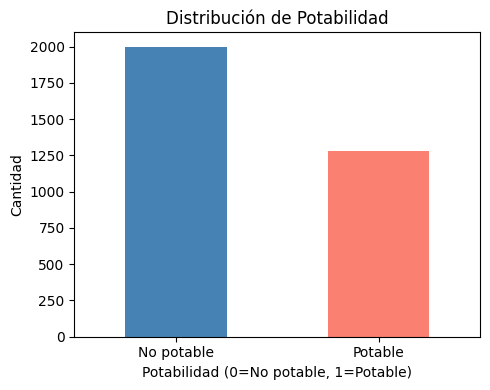

In [5]:
fig, ax = plt.subplots(figsize=(5, 4))
df['Potability'].value_counts().plot(kind='bar', color=['steelblue', 'salmon'], ax=ax)
ax.set_title('Distribución de Potabilidad')
ax.set_xlabel('Potabilidad (0=No potable, 1=Potable)')
ax.set_ylabel('Cantidad')
ax.set_xticklabels(['No potable', 'Potable'], rotation=0)
plt.tight_layout()
plt.savefig('../results/figures/distribucion_potabilidad.png', dpi=150)
plt.show()

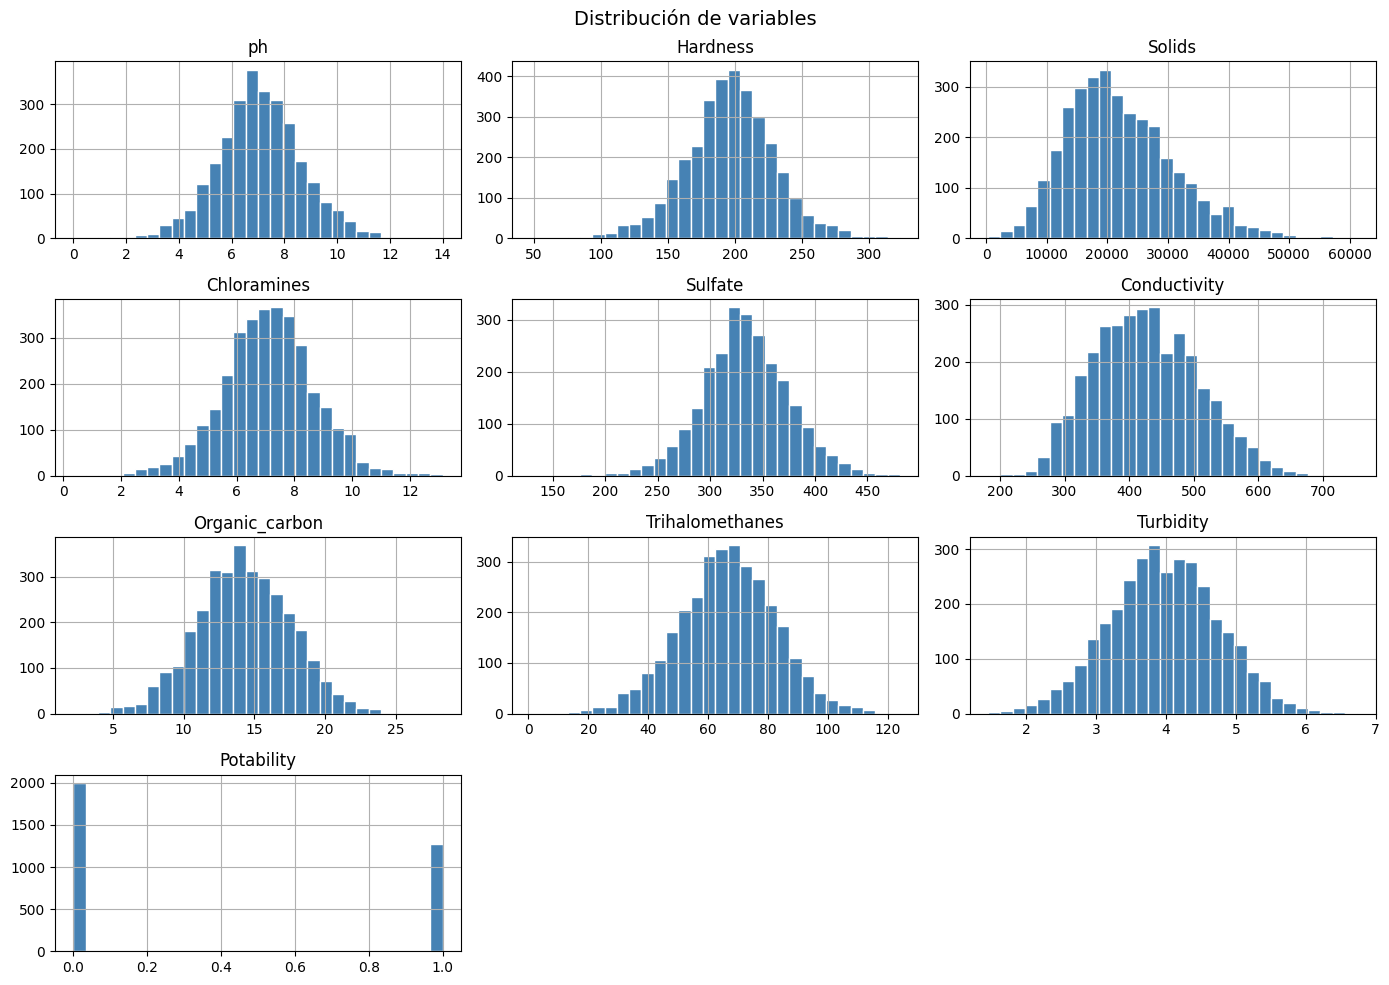

In [6]:
df.hist(figsize=(14, 10), bins=30, color='steelblue', edgecolor='white')
plt.suptitle('Distribución de variables', fontsize=14)
plt.tight_layout()
plt.savefig('../results/figures/histogramas_variables.png', dpi=150)
plt.show()

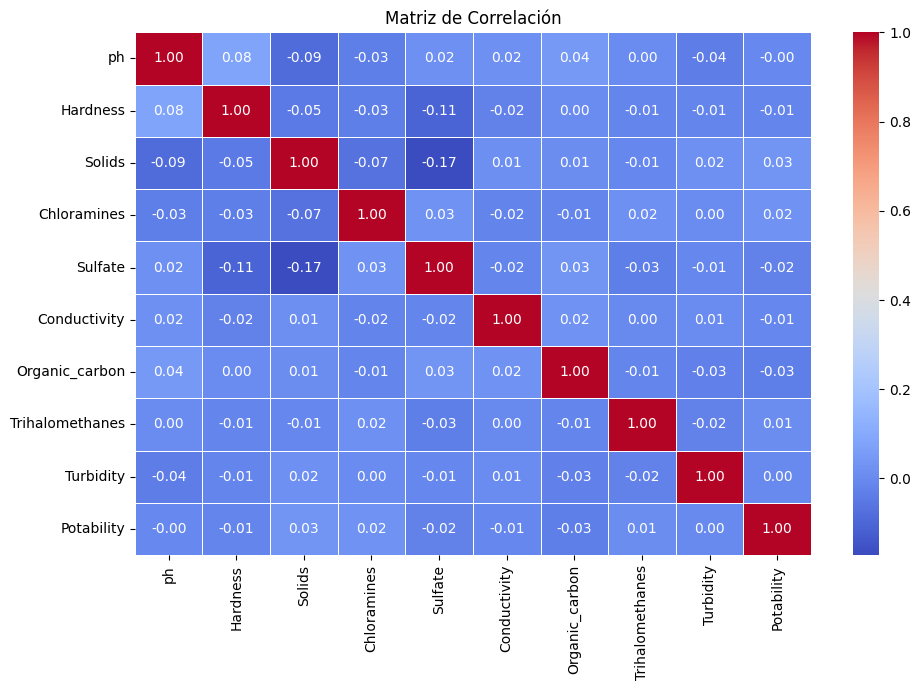

In [8]:
plt.figure(figsize=(10, 7))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title('Matriz de Correlación')
plt.tight_layout()
plt.savefig('../results/figures/correlacion.png', dpi=150)
plt.show()

C:\Users\Bianca\AppData\Local\Temp\ipykernel_31020\2854352662.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Potability', y=col, data=df, ax=axes[i],
C:\Users\Bianca\AppData\Local\Temp\ipykernel_31020\2854352662.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Potability', y=col, data=df, ax=axes[i],
C:\Users\Bianca\AppData\Local\Temp\ipykernel_31020\2854352662.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Potability', y=col, data=df, ax=axes[i],
C:\Users\Bianca\AppData\Local\Temp\ipykernel_31020\2854352662.py:7: Futur

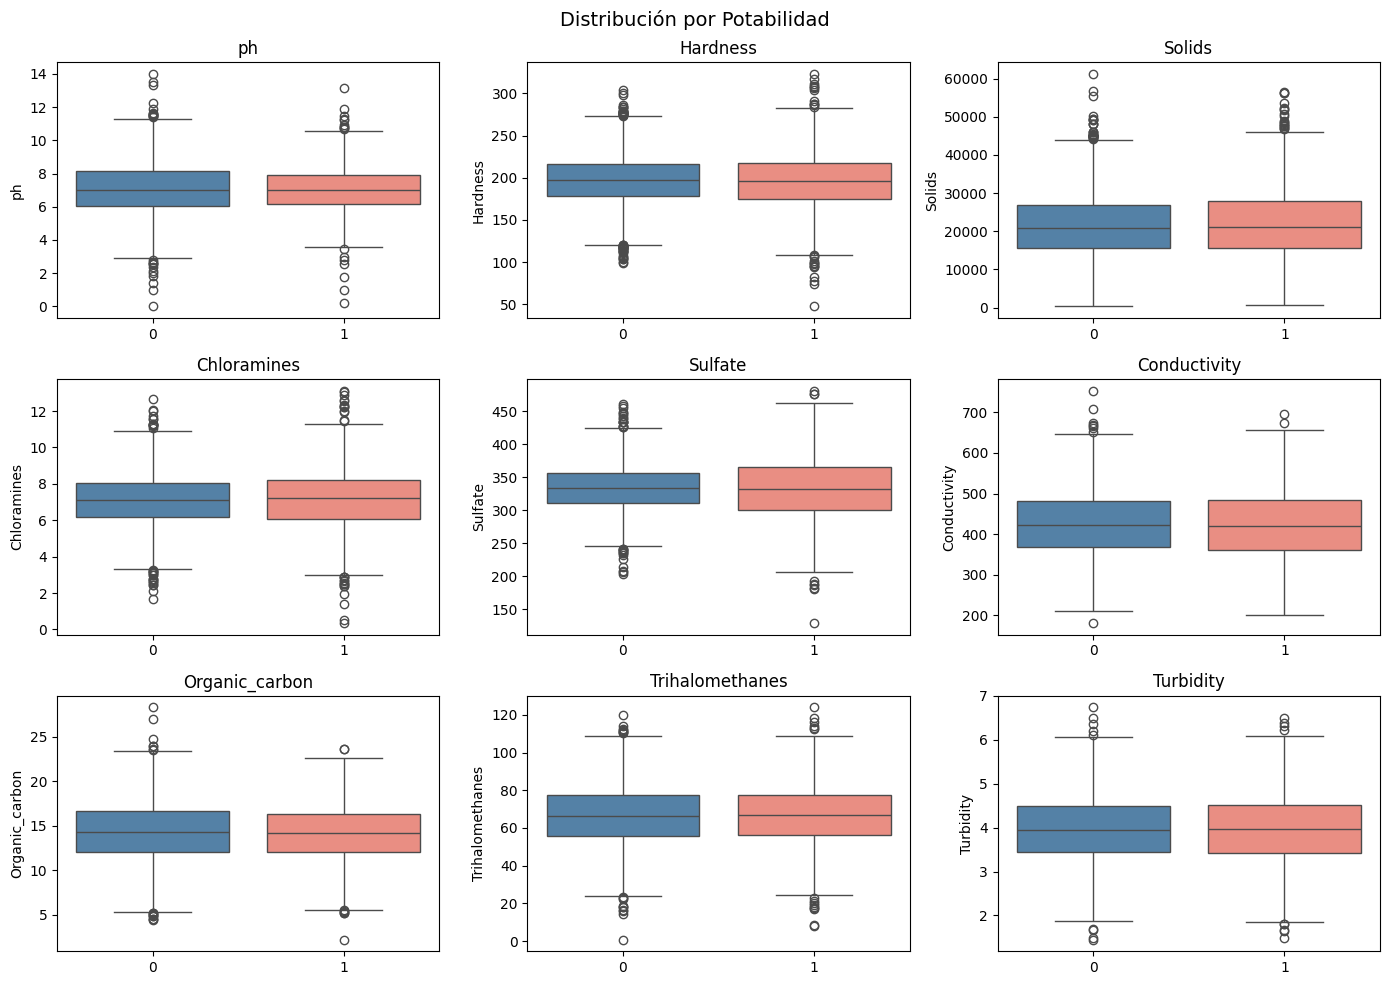

In [9]:
features = [col for col in df.columns if col != 'Potability']

fig, axes = plt.subplots(3, 3, figsize=(14, 10))
axes = axes.flatten()

for i, col in enumerate(features):
    sns.boxplot(x='Potability', y=col, data=df, ax=axes[i],
                palette=['steelblue', 'salmon'])
    axes[i].set_title(col)
    axes[i].set_xlabel('')

plt.suptitle('Distribución por Potabilidad', fontsize=14)
plt.tight_layout()
plt.savefig('../results/figures/boxplots_potabilidad.png', dpi=150)
plt.show()

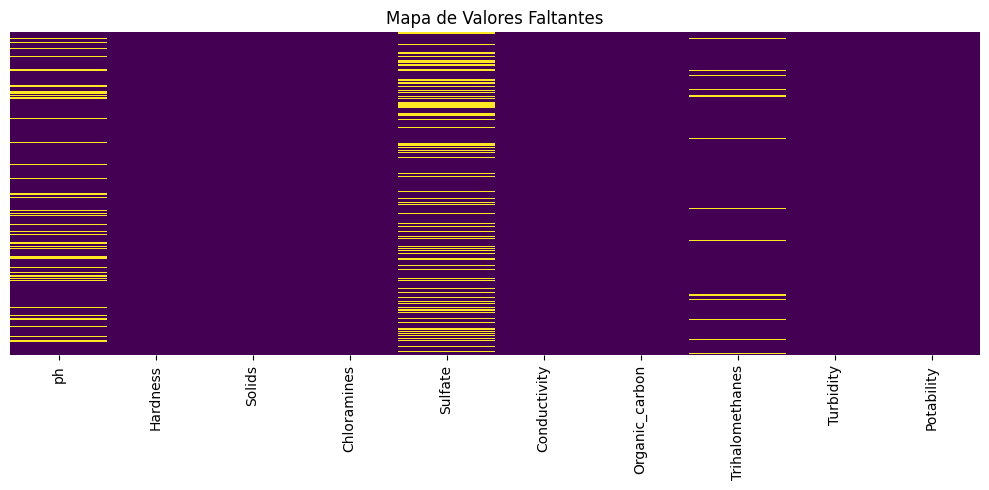

In [10]:
plt.figure(figsize=(10, 5))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis', yticklabels=False)
plt.title('Mapa de Valores Faltantes')
plt.tight_layout()
plt.savefig('../results/figures/mapa_faltantes.png', dpi=150)
plt.show()